# Crop-yield model development

The first notebook (`crop_yield_season_experiment.ipynb`) answered one question: do growing-season features beat the winter rows the label used to sit on? This one asks the next question: how much can a well-built model add on top of simple baselines, and how early in the season?

What changes from the first notebook:

- **Target:** each model predicts the season's relative gap to its own state-crop trend, not the raw yield. Raw yield is mostly "corn or soybean" plus a slow upward trend.
- **Features:** nine agronomic season features (`src/features.py`) built only from windows completed before a cut-off date.
- **Tuning:** every hyperparameter is picked by an inner leave-one-year-out loop on the training years only. When two settings tie, the simpler one wins.

The logic lives in `src/yield_model_development.py`; this notebook runs it piece by piece.

In [1]:
import os
import sys
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, display
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
sys.path.insert(0, str(Path("..") / "src"))
import features as ft
import season_yield_baselines as syb
import yield_model_development as ymd

DATA_DIR = Path(os.environ.get("TERRAYIELD_DATA_DIR", "../data"))
OUT_DIR = Path("../results")
gold = ymd.load_gold(DATA_DIR)

## Season features

One row per (state, crop, year). Windows count from April and must end before the cut-off; with no cut-off the season closes on 30 September. Corn and soybean in the same state share every feature, so there are really only 12 distinct feature rows behind the 24 labels.

In [2]:
table = ft.season_features(gold)
print(ft.describe_cutoffs(gold), "windows per season at each cut-off month")
table.round(3).head(6)

{7: [5, 6], 8: [7, 8], 9: [9, 10], 10: [11, 12]} windows per season at each cut-off month


,region,crop_type,year,ndvi_peak,ndvi_peak_doy,ndvi_integral,greenup_rate,gdd,hot_windows,tmax_avg,precip_total,radiation_total,windows,yield_t_ha
0,US-Illinois,corn,2020,0.813,223.0,5.389,0.235,1817.575,0.0,30.482,517.0,987733.0,11,11.989
1,US-Illinois,corn,2021,0.823,222.0,5.797,0.211,1889.432,2.0,30.900,644.1,946133.0,11,12.679
2,US-Illinois,corn,2022,0.839,221.0,5.830,0.244,1894.434,4.0,31.491,568.5,983304.0,11,12.909
3,US-Illinois,corn,2023,0.828,206.0,5.723,0.246,1897.470,2.0,31.409,432.2,1079734.0,11,12.930
4,US-Illinois,corn,2024,0.819,222.0,5.997,0.183,1936.113,1.0,31.318,481.0,1042350.0,11,13.621
5,US-Illinois,corn,2025,0.845,221.0,6.357,0.235,2021.456,1.0,31.008,480.6,1028521.0,12,13.432


## The model ladder

Baselines first (state-crop mean, previous season, linear trend), then four learners on the detrended target, plus one random forest on the raw yield level for comparison.

In [3]:
pred, chosen = ymd.run_ladder(table)
metrics = syb.summarise(pred)
metrics

,scheme,model,features,mae,rmse,mape_pct,mae_corn,mae_soybean,n_predictions
0,expanding_window,previous_season,none,0.261,0.332,4.25,0.267,0.256,16
1,expanding_window,region_crop_mean,none,0.422,0.514,4.74,0.666,0.178,16
2,expanding_window,random_forest,detrended,0.454,0.676,6.66,0.564,0.344,16
3,expanding_window,ridge,detrended,0.457,0.680,6.75,0.561,0.354,16
4,expanding_window,gradient_boosting,detrended,0.459,0.662,6.93,0.543,0.374,16
5,expanding_window,elastic_net,detrended,0.494,0.701,6.92,0.648,0.340,16
6,expanding_window,linear_trend,none,0.494,0.701,6.92,0.648,0.340,16
7,expanding_window,random_forest,raw_level,0.590,0.712,8.31,0.757,0.423,16
8,leave_one_year_out,gradient_boosting,detrended,0.314,0.460,4.31,0.417,0.211,24
9,leave_one_year_out,random_forest,detrended,0.315,0.466,4.37,0.415,0.215,24


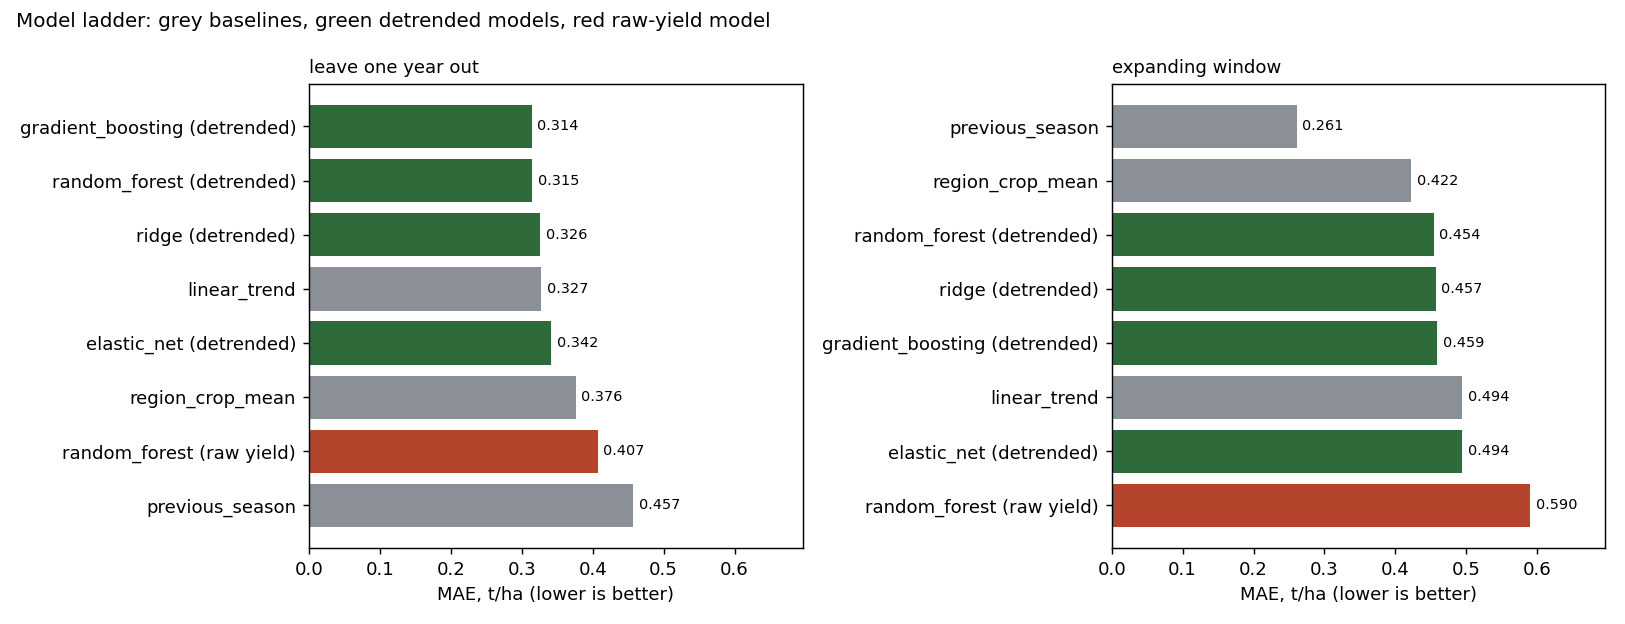

In [4]:
ymd.plot_ladder(metrics, OUT_DIR / "model_dev_ladder.png")
display(Image(filename=str(OUT_DIR / "model_dev_ladder.png")))

Which hyperparameters did the inner loop pick? Ridge chooses the strongest regularisation in most folds, which pulls it back towards the trend line. That alone says a lot about how much signal 24 seasons carry.

In [5]:
chosen[chosen["model"] == "ridge"].groupby("scheme")["alpha"].value_counts()

scheme              alpha
expanding_window    100.0    4
leave_one_year_out  100.0    4
                    30.0     2
Name: count, dtype: int64

## Two feature sets on equal terms

The plain June to September averages from the first notebook, run through exactly the same nested tuning.

In [6]:
ymd.compare_feature_sets(gold)

,feature_set,scheme,model,mae,rmse
0,plain Jun-Sep averages,expanding_window,gradient_boosting,0.474,0.679
1,plain Jun-Sep averages,expanding_window,ridge,0.480,0.693
2,plain Jun-Sep averages,leave_one_year_out,ridge,0.294,0.435
3,plain Jun-Sep averages,leave_one_year_out,gradient_boosting,0.301,0.426
4,agronomic season features,expanding_window,ridge,0.457,0.680
5,agronomic season features,expanding_window,gradient_boosting,0.459,0.662
6,agronomic season features,leave_one_year_out,gradient_boosting,0.314,0.460
7,agronomic season features,leave_one_year_out,ridge,0.326,0.457


## In-season: how early does the season tell you anything?

Same ridge model, features cut off at 1 July, 1 August, 1 September and 1 October. The yield report itself only lands in December, so none of these see the answer.

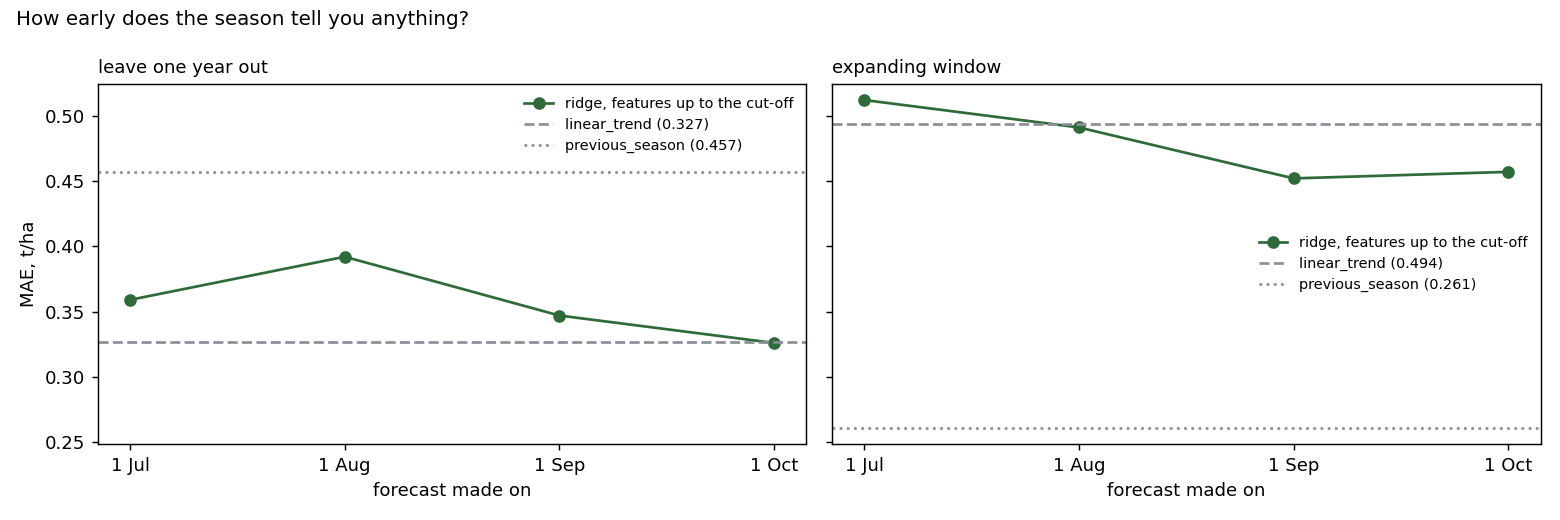

scheme,expanding_window,leave_one_year_out
cutoff,,
1 Jul,0.512,0.359
1 Aug,0.491,0.392
1 Sep,0.452,0.347
1 Oct,0.457,0.326


In [7]:
in_season = ymd.run_in_season(gold)
ymd.plot_in_season(in_season, metrics, OUT_DIR / "model_dev_in_season.png")
display(Image(filename=str(OUT_DIR / "model_dev_in_season.png")))
in_season[in_season["model"] == "ridge"].pivot(index="cutoff", columns="scheme", values="mae").loc[list(ymd.CUTOFFS.values())]

## What is the ridge model leaning on?

Coefficients are in percent of trend yield per standard deviation of the feature. "Same sign" is the share of leave-one-year-out refits that agree with the full-data sign. The last column is how much the leave-one-year-out MAE rises when that feature is removed (negative means the model does better without it).

In [8]:
importance, alpha, base = ymd.ridge_interpretation(table)
print("alpha chosen on full data:", alpha, "| LOYO MAE with all features:", round(base, 3))
importance

alpha chosen on full data: 100 | LOYO MAE with all features: 0.326


,feature,coef_pct_per_sd,same_sign_share_of_folds,mae_increase_when_dropped
0,ndvi_peak,-0.130,1.00,0.0347
1,ndvi_integral,-0.043,0.83,0.0035
2,greenup_rate,-0.055,0.83,0.0021
3,ndvi_peak_doy,0.171,1.00,-0.0030
4,radiation_total,-0.091,0.83,-0.0054
5,tmax_avg,0.286,0.83,-0.0063
6,precip_total,-0.005,0.67,-0.0110
7,hot_windows,0.170,0.67,-0.0111
8,gdd,0.104,0.83,-0.0131


## Where the errors are

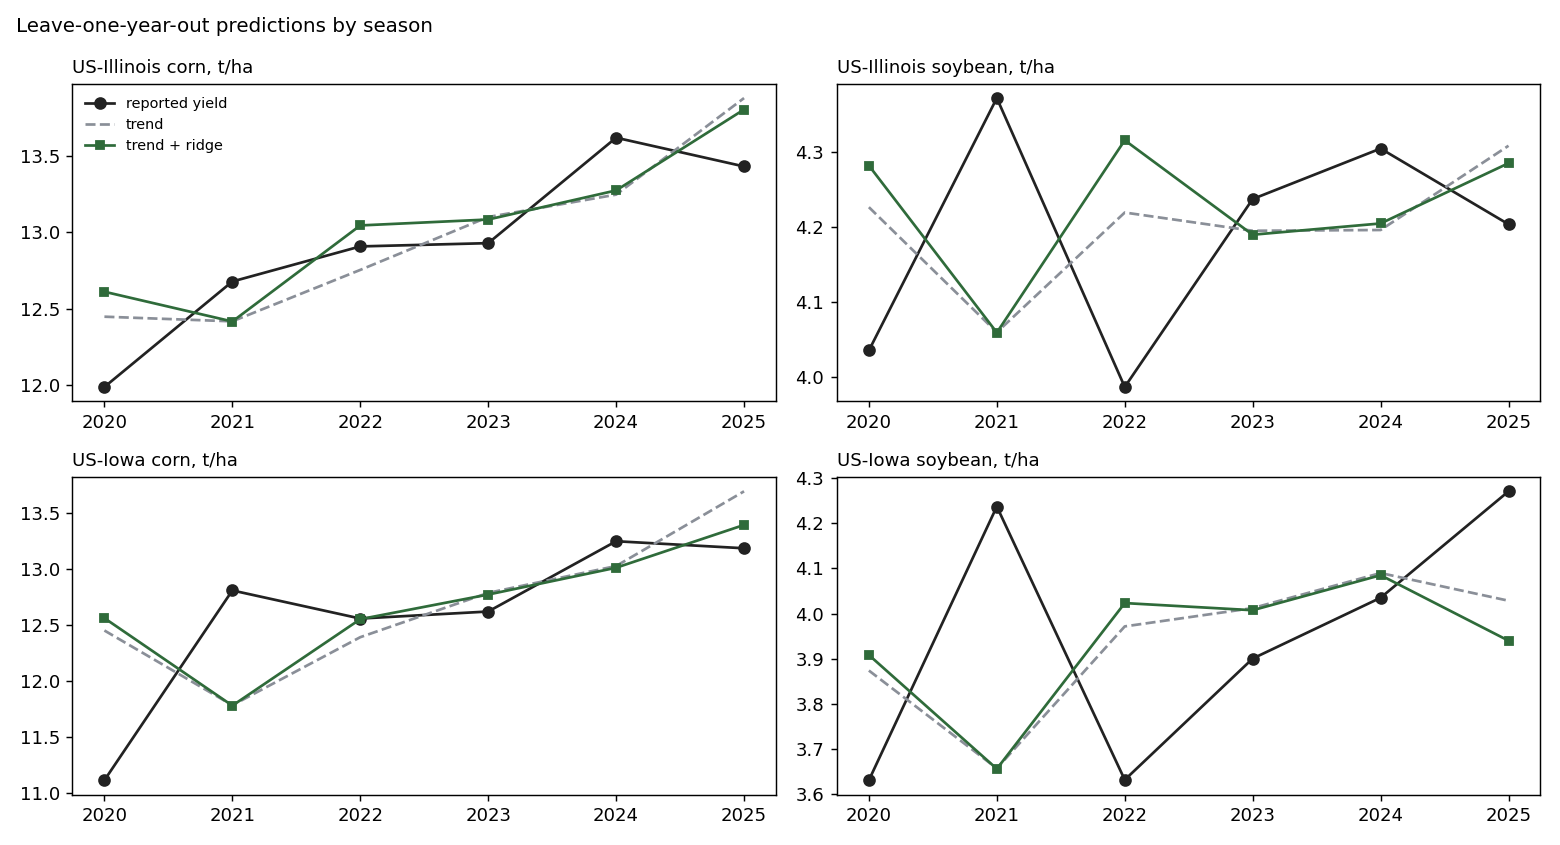

,region,crop_type,test_year,linear_trend,ridge,ridge_minus_trend
12,US-Iowa,corn,2020,1.337,1.447,0.110
13,US-Iowa,corn,2021,1.025,1.029,0.004
19,US-Iowa,soybean,2021,0.579,0.580,0.001
17,US-Iowa,corn,2025,0.508,0.208,-0.300
0,US-Illinois,corn,2020,0.460,0.623,0.163


In [9]:
ymd.plot_series(pred, OUT_DIR / "model_dev_predictions_by_season.png")
display(Image(filename=str(OUT_DIR / "model_dev_predictions_by_season.png")))
errors = pd.read_csv(OUT_DIR / "model_dev_errors_by_season.csv")
errors.sort_values("linear_trend", ascending=False).head(5)

## Sensitivity: without the flagged Iowa soybean 2022 value

The project had flagged this season as a possible census/survey mix-up. Dropping it doesn't change the ranking.

In [10]:
flagged = (table["region"] == "US-Iowa") & (table["crop_type"] == "soybean") & (table["year"] == 2022)
sens, _ = ymd.run_ladder(table[~flagged], schemes=("leave_one_year_out",), include_raw=False)
syb.summarise(sens)

,scheme,model,features,mae,rmse,mape_pct,mae_corn,mae_soybean,n_predictions
0,leave_one_year_out,gradient_boosting,detrended,0.314,0.469,4.36,0.393,0.226,23
1,leave_one_year_out,random_forest,detrended,0.330,0.468,4.54,0.420,0.231,23
2,leave_one_year_out,ridge,detrended,0.331,0.454,4.61,0.412,0.242,23
3,leave_one_year_out,linear_trend,none,0.337,0.450,4.51,0.441,0.224,23
4,leave_one_year_out,elastic_net,detrended,0.350,0.458,4.69,0.456,0.234,23
5,leave_one_year_out,region_crop_mean,none,0.374,0.565,4.55,0.542,0.191,23
6,leave_one_year_out,previous_season,none,0.449,0.654,5.74,0.618,0.266,23


## What I take from this

- **Detrending is the single biggest win.** The same random forest goes from 0.407 to 0.315 t/ha (leave-one-year-out) and from 0.590 to 0.454 (expanding window) just by predicting the gap to trend instead of the raw yield.
- **On top of the trend, the features add a little, not a lot.** The best retrospective model (gradient boosting, 0.314) beats the trend (0.327) by about 4%, with the random forest right behind (0.315). Ridge, tuned without seeing the test year, lands on the trend itself (0.326).
- **For a forecast, last year's yield still wins.** Ridge, random forest and gradient boosting all beat the trend under the expanding window (0.454 to 0.459 against 0.494), while elastic net shrinks back to it. None gets near the previous-season baseline (0.261).
- **The season only starts to help late.** Under leave-one-year-out the in-season ridge never gets meaningfully ahead of the trend (its best is 0.326 against 0.327). Under the expanding window it's level with the trend on 1 August and clearly ahead from 1 September (0.452 against 0.494).
- **The model isn't learning agronomy.** The coefficients are a fraction of a percent of yield, only peak NDVI clearly earns its place, and some signs run against intuition. With 12 distinct feature rows that's expected.
- **The biggest miss is Iowa corn 2020** (1.34 t/ha for the trend, 1.45 for ridge). That was the season of the August derecho, which flattened corn across central Iowa right around the canopy peak, on top of a dry summer. A statewide 16-day NDVI mean barely registers damage like that.

None of this says satellite features are useless for yield. It says 24 state-level seasons can't show what they're worth. County-level labels are the next step.